<a href="https://colab.research.google.com/github/il1yasvie1/special-finite-element-methods/blob/main/special_FEMs_v1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
try:
    import firedrake
except ImportError:
    !wget "https://fem-on-colab.github.io/releases/firedrake-install-release-real.sh" -O "/tmp/firedrake-install.sh" && bash "/tmp/firedrake-install.sh"
    import firedrake

In [2]:
from firedrake import *
from firedrake.pyplot import triplot
from firedrake.pyplot import tricontourf

import numpy as np
import scipy
from matplotlib import pyplot as plt

In [3]:
np.random.seed(0)
ε = 1e-2
a_expr = np.vectorize(lambda x: 1 / (1 + 0.5*np.sin(2*np.pi*x/ε)) + (1.0 if x < 0.25 else 0.0) + (10.0 if x > 0.75 else 0.0))
# a_expr = np.vectorize(lambda x: 1 / (1 + 0.5*np.sin(2*np.pi*x/ε)) + ((1 + .5*np.random.rand()) if x < 0.25 else 0.0)) # test the randomness, should be removed as a(x, y) only varies in x direction

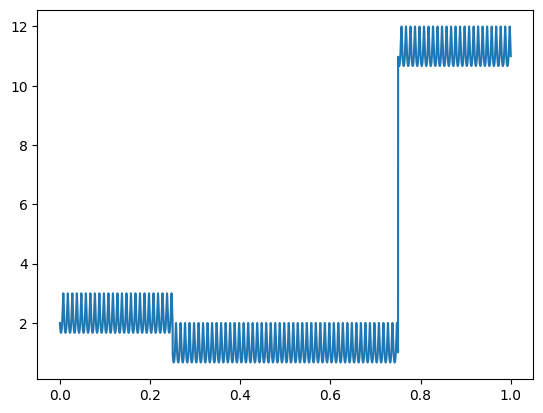

In [4]:
N = int(100/ε)
x = np.linspace(0, 1, N)
plt.plot(x, a_expr(x))
plt.show()

In [5]:
ξ = np.vectorize(lambda x: scipy.integrate.quad(lambda x: 1/a_expr(x), 0, x)[0])
sol = scipy.integrate.solve_ivp(lambda t, y: a_expr(y), [0, ξ(1) + ε], [0],
                                max_step=ε/10)

ξ_inv = scipy.interpolate.interp1d(sol.t, sol.y.reshape(-1,))

/tmp/ipython-input-310351437.py:1: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  ξ = np.vectorize(lambda x: scipy.integrate.quad(lambda x: 1/a_expr(x), 0, x)[0])


In [6]:
mesh_ = UnitSquareMesh(32, 8, quadrilateral=False)
mesh_.coordinates.dat.data[:, 0] *= ξ(1)
coords_ = mesh_.coordinates.dat.data
V_ = FunctionSpace(mesh_, 'CG', 1)

/tmp/ipython-input-310351437.py:1: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  ξ = np.vectorize(lambda x: scipy.integrate.quad(lambda x: 1/a_expr(x), 0, x)[0])


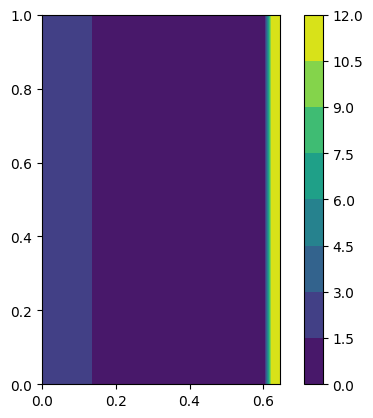

In [7]:
a_func = Function(V_)
a_func.dat.data[:] = a_expr(ξ_inv(coords_[:, 0]))

fig, axes = plt.subplots()
contours = tricontourf(a_func, axes=axes)
axes.set_aspect("equal")
fig.colorbar(contours)
fig.show()

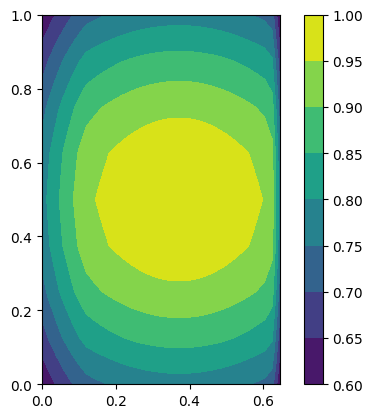

In [8]:
f_expr = lambda x, y: np.exp(-(x-0.5)**2 - (y-0.5)**2)
f_func = Function(V_)
f_func.dat.data[:] = f_expr(ξ_inv(coords_[:, 0]), coords_[:, 1])

fig, axes = plt.subplots()
contours = tricontourf(f_func, axes=axes)
axes.set_aspect("equal")
fig.colorbar(contours)
fig.show()

In [9]:
u_func = Function(V_)
uh = TrialFunction(V_)
vh = TestFunction(V_)

Buv = (Dx(uh, 0)*Dx(vh, 0) + a_func**2 * Dx(uh, 1)*Dx(vh, 1))*dx
Lv = a_func*f_func*vh*dx

solve(Buv == Lv, u_func, bcs = DirichletBC(V_, 0, "on_boundary"))

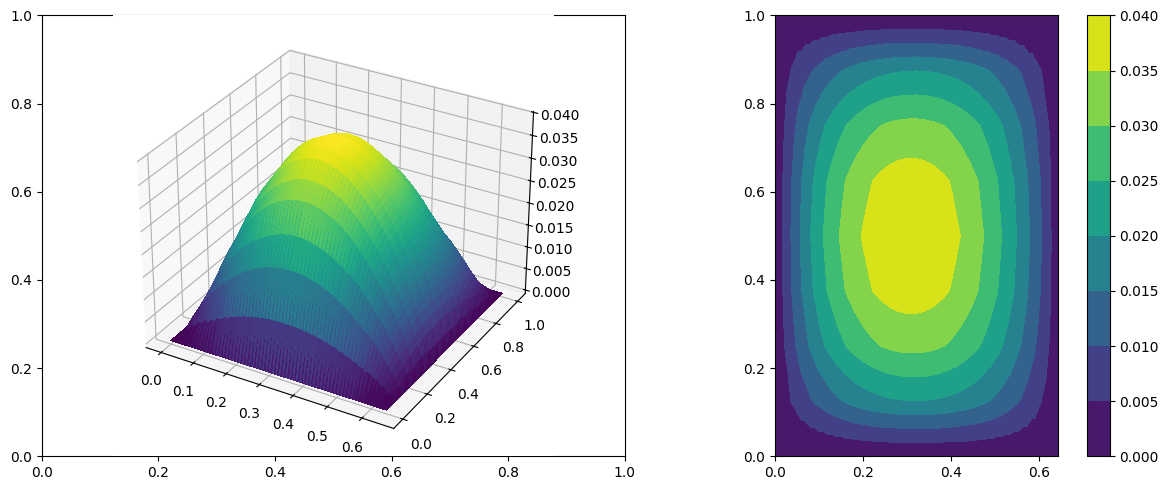

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1 = fig.add_subplot(121, projection='3d')
ts = trisurf(u_func, axes=ax1)
contours = tricontourf(u_func, axes=ax2)
ax2.set_aspect("equal")
fig.colorbar(contours, ax=ax2)
plt.tight_layout()
plt.show()

In [11]:
Vc_ = mesh_.coordinates.function_space()
ψ = Function(Vc_)
ψ.dat.data[:, 0] = ξ_inv(mesh_.coordinates.dat.data[:, 0])
ψ.dat.data[:, 1] = mesh_.coordinates.dat.data[:, 1]
mesh = Mesh(Function(ψ))

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


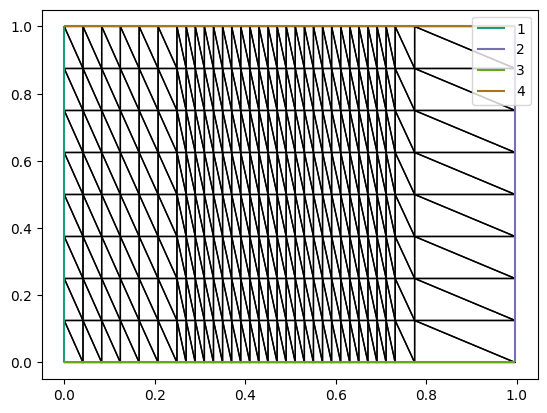

In [12]:
fig, axes = plt.subplots()
triplot(mesh, axes=axes)
axes.legend()
fig.show()

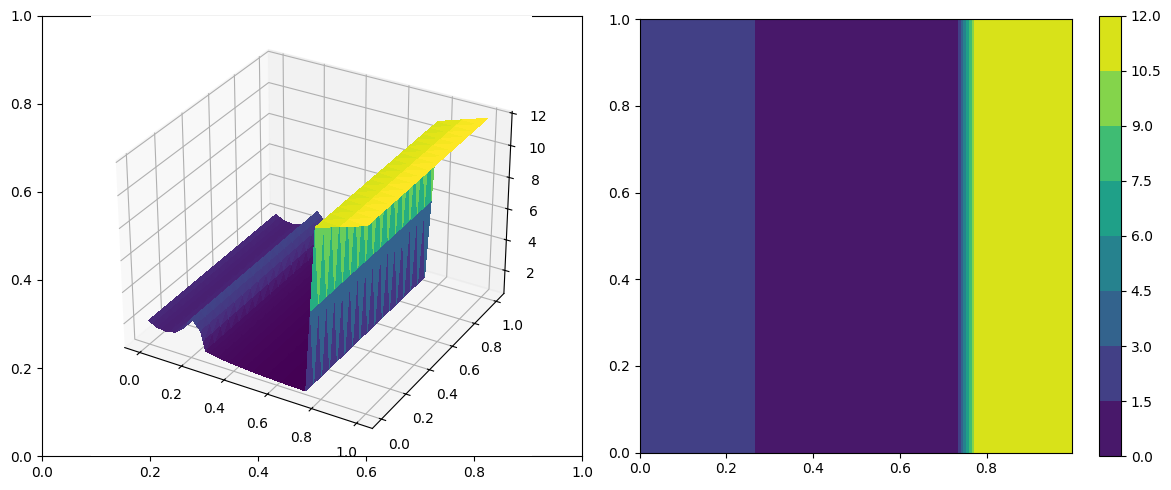

In [13]:
V = FunctionSpace(mesh, 'CG', 1)

a = Function(V).interpolate(a_func)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1 = fig.add_subplot(121, projection='3d')
ts = trisurf(a, axes=ax1)
contours = tricontourf(a, axes=ax2)
ax2.set_aspect("equal")
fig.colorbar(contours, ax=ax2)
plt.tight_layout()
plt.show()

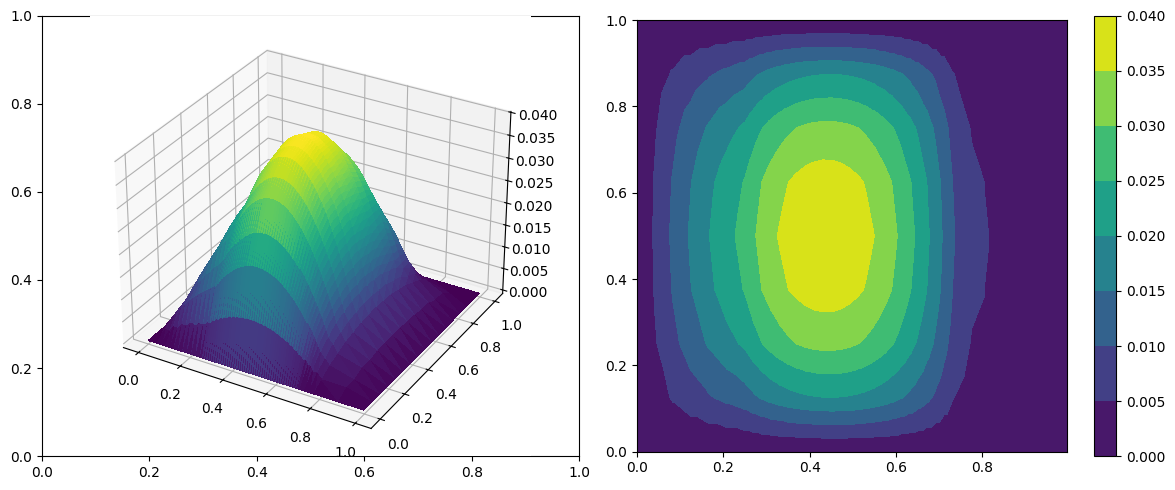

In [14]:
u = Function(V).interpolate(u_func)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1 = fig.add_subplot(121, projection='3d')
ts = trisurf(u, axes=ax1)
contours = tricontourf(u, axes=ax2)
ax2.set_aspect("equal")
fig.colorbar(contours, ax=ax2)
plt.tight_layout()
plt.show()